# Secure MNIST — Person 2

Responsibilities:
- STRIDE threat modeling and OWASP ML mapping
- Attacker model and LINDDUN privacy discussion
- SAST findings and remediation
- Training-data poisoning
- Dataset-integrity defense
- Security evaluation

Current experiment:
Targeted label flipping from digit 1 to digit 7.

Only training labels may be modified.
Validation and test data must remain untouched.

CNN and training configuration are provisional until team agreement.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Secure_MNIST_Person2"
)

for folder in [
    "config",
    "trusted",
    "attacks",
    "results",
    "sast",
    "src",
]:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)

Project folder: /content/drive/MyDrive/Secure_MNIST_Person2


In [ ]:
import sys
import random
import numpy as np
import torch
import torchvision

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("CUDA available:", torch.cuda.is_available())

Python: 3.13.16
PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
NumPy: 2.1.3
CUDA available: False


In [ ]:
from torchvision.datasets import MNIST

# Download to temporary Colab storage.
# Persistent experiment records will be saved to Google Drive.
DATA_DIR = Path("/content/mnist_data")

official_train = MNIST(
    root=str(DATA_DIR),
    train=True,
    download=True,
)

official_test = MNIST(
    root=str(DATA_DIR),
    train=False,
    download=True,
)

# Canonical raw representation:
# images: uint8, shape [N, 28, 28]
# labels: int64, shape [N]
all_train_images = official_train.data.numpy().copy()
all_train_labels = official_train.targets.numpy().copy()

test_images = official_test.data.numpy().copy()
test_labels = official_test.targets.numpy().copy()

# Independent generator keeps this split reproducible.
split_generator = torch.Generator().manual_seed(SEED)
permutation = torch.randperm(
    len(all_train_labels),
    generator=split_generator,
).numpy()

train_indices = permutation[:55_000]
val_indices = permutation[55_000:]

train_images = all_train_images[train_indices].copy()
train_labels = all_train_labels[train_indices].copy()

val_images = all_train_images[val_indices].copy()
val_labels = all_train_labels[val_indices].copy()

# Explicit checks are retained even if Python runs with optimization.
if np.intersect1d(train_indices, val_indices).size != 0:
    raise RuntimeError("Training and validation indices overlap.")

if len(train_indices) + len(val_indices) != 60_000:
    raise RuntimeError("The split does not cover the training dataset.")

print("Training images:", train_images.shape)
print("Validation images:", val_images.shape)
print("Test images:", test_images.shape)

print("\nTraining class counts:")
print(np.bincount(train_labels, minlength=10))

100%|██████████| 9.91M/9.91M [00:00<00:00, 21.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 550kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.58MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.4MB/s]

Training images: (55000, 28, 28)
Validation images: (5000, 28, 28)
Test images: (10000, 28, 28)

Training class counts:
[5441 6190 5477 5600 5346 5000 5422 5710 5347 5467]


In [ ]:
import json
import hashlib

def array_digest(array):
    """Hash shape, dtype, and canonical array bytes."""
    array = np.ascontiguousarray(array)

    metadata = json.dumps(
        {
            "shape": list(array.shape),
            "dtype": array.dtype.str,
        },
        sort_keys=True,
        separators=(",", ":"),
    ).encode("utf-8")

    digest = hashlib.sha256()
    digest.update(metadata)
    digest.update(b"\0")
    digest.update(array.tobytes(order="C"))
    return digest.hexdigest()


split_path = PROJECT_DIR / "config" / "split_indices.npz"
reference_path = PROJECT_DIR / "trusted" / "clean_reference.json"

reference = {
    "split_seed": SEED,
    "train_size": len(train_labels),
    "validation_size": len(val_labels),
    "test_size": len(test_labels),
    "train_images_sha256": array_digest(train_images),
    "train_labels_sha256": array_digest(train_labels),
    "validation_images_sha256": array_digest(val_images),
    "validation_labels_sha256": array_digest(val_labels),
    "test_images_sha256": array_digest(test_images),
    "test_labels_sha256": array_digest(test_labels),
}

# Avoid silently overwriting an existing trusted reference.
if reference_path.exists():
    existing_reference = json.loads(reference_path.read_text())

    if existing_reference != reference:
        raise RuntimeError(
            "Existing trusted reference differs. "
            "Investigate before replacing it."
        )

    print("Existing clean reference matches.")
else:
    with reference_path.open("x") as handle:
        json.dump(reference, handle, indent=2)

    print("Created clean reference.")

if split_path.exists():
    with np.load(split_path, allow_pickle=False) as saved:
        split_matches = (
            np.array_equal(saved["train_indices"], train_indices)
            and np.array_equal(saved["val_indices"], val_indices)
        )

    if not split_matches:
        raise RuntimeError("Existing saved split differs.")
else:
    np.savez_compressed(
        split_path,
        train_indices=train_indices,
        val_indices=val_indices,
    )

print("Split and clean reference are ready.")

Created clean reference.
Split and clean reference are ready.


In [ ]:
def targeted_label_flip(
    clean_labels,
    source_class=1,
    target_class=7,
    fraction=0.30,
    seed=42,
):
    if not 0 <= fraction <= 1:
        raise ValueError("fraction must be between 0 and 1.")

    if source_class == target_class:
        raise ValueError("Source and target classes must differ.")

    eligible_indices = np.flatnonzero(
        clean_labels == source_class
    )

    number_to_flip = int(
        np.floor(fraction * len(eligible_indices))
    )

    rng = np.random.default_rng(seed)

    selected_indices = np.sort(
        rng.choice(
            eligible_indices,
            size=number_to_flip,
            replace=False,
        )
    )

    poisoned_labels = clean_labels.copy()
    poisoned_labels[selected_indices] = target_class

    return poisoned_labels, selected_indices


poisoned_labels, poisoned_indices = targeted_label_flip(
    train_labels,
    source_class=1,
    target_class=7,
    fraction=0.30,
    seed=SEED,
)

changed_indices = np.flatnonzero(
    poisoned_labels != train_labels
)

if not np.array_equal(changed_indices, poisoned_indices):
    raise RuntimeError("Unexpected labels were changed.")

print("Eligible class 1 records:", int((train_labels == 1).sum()))
print("Modified records:", len(poisoned_indices))
print(
    "Modified fraction of entire training set:",
    f"{len(poisoned_indices) / len(train_labels):.2%}",
)
print("Original labels:", train_labels[poisoned_indices[:10]])
print("Poisoned labels:", poisoned_labels[poisoned_indices[:10]])

Eligible class 1 records: 6190
Modified records: 1857
Modified fraction of entire training set: 3.38%
Original labels: [1 1 1 1 1 1 1 1 1 1]
Poisoned labels: [7 7 7 7 7 7 7 7 7 7]


In [ ]:
attack_path = (
    PROJECT_DIR / "attacks" / "label_flip_1_to_7_fraction_030.npz"
)

np.savez_compressed(
    attack_path,
    poisoned_labels=poisoned_labels,
    changed_training_positions=poisoned_indices,
    original_mnist_indices=train_indices[poisoned_indices],
    original_labels=train_labels[poisoned_indices],
    replacement_labels=poisoned_labels[poisoned_indices],
)

checks = {
    "clean_training_images_unchanged": (
        array_digest(train_images)
        == reference["train_images_sha256"]
    ),
    "clean_training_labels_unchanged": (
        array_digest(train_labels)
        == reference["train_labels_sha256"]
    ),
    "validation_images_unchanged": (
        array_digest(val_images)
        == reference["validation_images_sha256"]
    ),
    "validation_labels_unchanged": (
        array_digest(val_labels)
        == reference["validation_labels_sha256"]
    ),
    "test_images_unchanged": (
        array_digest(test_images)
        == reference["test_images_sha256"]
    ),
    "test_labels_unchanged": (
        array_digest(test_labels)
        == reference["test_labels_sha256"]
    ),
    "poisoned_labels_detected_as_different": (
        array_digest(poisoned_labels)
        != reference["train_labels_sha256"]
    ),
}

for name, passed in checks.items():
    print(f"{name}: {'PASS' if passed else 'FAIL'}")

if not all(checks.values()):
    raise RuntimeError("Experiment isolation checks failed.")

print("\nSaved attack evidence:", attack_path.name)

clean_training_images_unchanged: PASS
clean_training_labels_unchanged: PASS
validation_images_unchanged: PASS
validation_labels_unchanged: PASS
test_images_unchanged: PASS
test_labels_unchanged: PASS
poisoned_labels_detected_as_different: PASS

Saved attack evidence: label_flip_1_to_7_fraction_030.npz


Load the saved trusted reference

In [ ]:
# Load the previously established reference.
# Do not regenerate expected hashes from the candidate data.

reference_path = PROJECT_DIR / "trusted" / "clean_reference.json"

trusted_reference = json.loads(reference_path.read_text())

print("Trusted reference loaded.")
print("Expected training records:", trusted_reference["train_size"])

Trusted reference loaded.
Expected training records: 55000


**Create the training gate**:
This gate checks the candidate training images and labels against the trusted snapshot. If either differs, it blocks training.

In [ ]:
class DatasetIntegrityError(RuntimeError):
    """Raised when candidate training data fails verification."""


def verify_training_data(images, labels, trusted_reference):
    checks = {
        "image_count_matches": (
            len(images) == trusted_reference["train_size"]
        ),
        "label_count_matches": (
            len(labels) == trusted_reference["train_size"]
        ),
        "images_match_trusted_snapshot": (
            array_digest(images)
            == trusted_reference["train_images_sha256"]
        ),
        "labels_match_trusted_snapshot": (
            array_digest(labels)
            == trusted_reference["train_labels_sha256"]
        ),
    }

    return {
        "accepted": all(checks.values()),
        "checks": checks,
    }


def require_verified_training_data(images, labels, trusted_reference):
    result = verify_training_data(
        images, labels, trusted_reference
    )

    if not result["accepted"]:
        failed = [
            name
            for name, passed in result["checks"].items()
            if not passed
        ]

        raise DatasetIntegrityError(
            "Training blocked. Failed checks: " + ", ".join(failed)
        )

    return result

Confirm that clean data passes and poisoned data is blocked

In [ ]:
clean_gate_result = require_verified_training_data(
    train_images,
    train_labels,
    trusted_reference,
)

print("Clean data: ACCEPTED")

try:
    require_verified_training_data(
        train_images,
        poisoned_labels,
        trusted_reference,
    )
except DatasetIntegrityError as error:
    print("Poisoned data: BLOCKED")
    print(error)
else:
    raise RuntimeError(
        "Defense failed: poisoned data was accepted."
    )

Clean data: ACCEPTED
Poisoned data: BLOCKED
Training blocked. Failed checks: labels_match_trusted_snapshot


**Generate the three poisoning levels:**
We’ll use nested attack sets, the records modified at 10% are also modified at 30% and 50%. This gives a more controlled comparison as the poisoning budget increases.

In [ ]:
import math

SOURCE_CLASS = 1
TARGET_CLASS = 7
FRACTIONS = [0.10, 0.30, 0.50]
ATTACK_SEED = 42

eligible_indices = np.flatnonzero(
    train_labels == SOURCE_CLASS
)

attack_rng = np.random.default_rng(ATTACK_SEED)
attack_order = attack_rng.permutation(eligible_indices)

poisoned_variants = {}
attack_summary = []

for fraction in FRACTIONS:
    number_to_flip = math.floor(
        fraction * len(eligible_indices)
    )

    selected = np.sort(attack_order[:number_to_flip])

    candidate_labels = train_labels.copy()
    candidate_labels[selected] = TARGET_CLASS

    actual_changes = np.flatnonzero(
        candidate_labels != train_labels
    )

    if not np.array_equal(actual_changes, selected):
        raise RuntimeError("Unexpected modified records.")

    fraction_tag = f"{round(fraction * 100):03d}"

    # New filenames preserve the earlier standalone experiment.
    output_path = PROJECT_DIR / "attacks" / (
        f"nested_label_flip_1_to_7_fraction_{fraction_tag}.npz"
    )

    np.savez_compressed(
        output_path,
        poisoned_labels=candidate_labels,
        changed_training_positions=selected,
        original_mnist_indices=train_indices[selected],
        original_labels=train_labels[selected],
        replacement_labels=candidate_labels[selected],
        requested_source_fraction=np.float64(fraction),
        attack_seed=np.int64(ATTACK_SEED),
    )

    poisoned_variants[fraction_tag] = {
        "labels": candidate_labels,
        "indices": selected,
    }

    attack_summary.append({
        "fraction_tag": fraction_tag,
        "source_class": SOURCE_CLASS,
        "target_class": TARGET_CLASS,
        "eligible_records": len(eligible_indices),
        "modified_records": len(selected),
        "source_class_fraction": len(selected) / len(eligible_indices),
        "whole_training_fraction": len(selected) / len(train_labels),
        "attack_seed": ATTACK_SEED,
        "artifact": output_path.name,
    })

    print(
        f"{fraction:.0%} of class 1: "
        f"{len(selected)} modified; "
        f"{len(selected) / len(train_labels):.2%} of training set"
    )

10% of class 1: 619 modified; 1.13% of training set
30% of class 1: 1857 modified; 3.38% of training set
50% of class 1: 3095 modified; 5.63% of training set


Evaluate the gate on all variants and save evidence

In [ ]:
from time import perf_counter

gate_results = []

candidates = {"clean": train_labels}
candidates.update({
    f"poisoned_{tag}": variant["labels"]
    for tag, variant in poisoned_variants.items()
})

for name, candidate_labels in candidates.items():
    started = perf_counter()

    result = verify_training_data(
        train_images,
        candidate_labels,
        trusted_reference,
    )

    elapsed_ms = (perf_counter() - started) * 1000

    expected_acceptance = name == "clean"

    if result["accepted"] != expected_acceptance:
        raise RuntimeError(
            f"Unexpected integrity decision for {name}."
        )

    gate_results.append({
        "condition": name,
        "accepted": result["accepted"],
        "checks": result["checks"],
        "verification_ms": elapsed_ms,
    })

    decision = "ACCEPTED" if result["accepted"] else "BLOCKED"

    print(f"{name}: {decision} ({elapsed_ms:.2f} ms)")

summary_path = PROJECT_DIR / "results" / "attack_summary.json"
summary_path.write_text(json.dumps(attack_summary, indent=2))

gate_path = PROJECT_DIR / "results" / "integrity_gate_results.json"
gate_path.write_text(json.dumps(gate_results, indent=2))

print("\nSaved attack summary and integrity gate results.")

clean: ACCEPTED (72.62 ms)
poisoned_010: BLOCKED (67.65 ms)
poisoned_030: BLOCKED (67.10 ms)
poisoned_050: BLOCKED (137.32 ms)

Saved attack summary and integrity gate results.


Check that image changes are also blocked

In [ ]:
tampered_images = train_images.copy()

# Change exactly one pixel while keeping its value in uint8 range.
old_pixel = int(tampered_images[0, 0, 0])
tampered_images[0, 0, 0] = (old_pixel + 1) % 256

image_tamper_result = verify_training_data(
    tampered_images,
    train_labels,
    trusted_reference,
)

if image_tamper_result["accepted"]:
    raise RuntimeError("Defense failed: image tampering was accepted.")

if image_tamper_result["checks"]["images_match_trusted_snapshot"]:
    raise RuntimeError("The modified image was not detected.")

print("Image tampering: BLOCKED")
print("Original training images still match:",
      array_digest(train_images)
      == trusted_reference["train_images_sha256"])

del tampered_images

Image tampering: BLOCKED
Original training images still match: True


Save a verified clean recovery copy. We retained the clean arrays before the attack.

In [ ]:
require_verified_training_data(
    train_images,
    train_labels,
    trusted_reference,
)

recovery_path = PROJECT_DIR / "trusted" / "clean_training_snapshot.npz"

if recovery_path.exists():
    # Validate an existing snapshot instead of silently replacing it.
    with np.load(recovery_path, allow_pickle=False) as saved:
        require_verified_training_data(
            saved["images"],
            saved["labels"],
            trusted_reference,
        )

    print("Existing recovery snapshot verified.")
else:
    # Exclusive creation prevents overwriting an existing file.
    with recovery_path.open("xb") as handle:
        np.savez_compressed(
            handle,
            images=train_images,
            labels=train_labels,
        )

    print("Clean recovery snapshot saved.")

Clean recovery snapshot saved.


Demonstrate block → restore → verify

In [ ]:
candidate_labels = poisoned_variants["030"]["labels"]

# First establish that the candidate cannot enter protected training.
try:
    require_verified_training_data(
        train_images,
        candidate_labels,
        trusted_reference,
    )
except DatasetIntegrityError:
    print("Step 1: Poisoned candidate blocked.")
else:
    raise RuntimeError("Poisoned candidate unexpectedly accepted.")

# Recover from the trusted snapshot.
with np.load(recovery_path, allow_pickle=False) as saved:
    recovered_images = saved["images"].copy()
    recovered_labels = saved["labels"].copy()

# Recovery is accepted only after verification.
recovery_result = require_verified_training_data(
    recovered_images,
    recovered_labels,
    trusted_reference,
)

print("Step 2: Trusted snapshot loaded.")
print("Step 3: Recovered data verified; eligible for training.")

recovery_evidence = {
    "poisoned_condition": "poisoned_030",
    "poisoned_candidate_blocked": True,
    "recovery_source": recovery_path.name,
    "recovered_data_accepted": recovery_result["accepted"],
    "recovery_checks": recovery_result["checks"],
    "used_attack_indices_for_recovery": False,
}

recovery_evidence_path = (
    PROJECT_DIR / "results" / "recovery_evidence.json"
)
recovery_evidence_path.write_text(
    json.dumps(recovery_evidence, indent=2)
)

print("Recovery evidence saved.")

Step 1: Poisoned candidate blocked.
Step 2: Trusted snapshot loaded.
Step 3: Recovered data verified; eligible for training.
Recovery evidence saved.


## Preliminary integrity-defense results

The clean training dataset passed verification. Three nested
label-flipping variants, modifying 619, 1,857, and 3,095 training
labels respectively, were rejected before protected training.

A separate one-pixel modification was also rejected. Recovery
loaded a previously verified clean snapshot and checked it against
the trusted reference before allowing training.

The control detects changes relative to a trusted snapshot. It
does not identify individual modified records, determine whether
the original source was poisoned, or protect against an attacker
who can also replace the trusted reference or verification code.

Classification impact has not yet been measured.

Save the reusable functions as a Python module

In [ ]:
import inspect
import ast

module_path = PROJECT_DIR / "src" / "data_security.py"

functions_to_export = [
    array_digest,
    targeted_label_flip,
    verify_training_data,
    require_verified_training_data,
]

module_parts = [
    '"""Training-data poisoning and integrity verification utilities."""\n',
    "import hashlib\nimport json\nimport numpy as np\n",
    (
        "class DatasetIntegrityError(RuntimeError):\n"
        '    """Raised when candidate training data fails verification."""\n'
        "    pass\n"
    ),
]

for function in functions_to_export:
    module_parts.append(inspect.getsource(function))

module_source = "\n\n".join(module_parts)

# Check Python syntax before saving.
ast.parse(module_source)

module_path.write_text(module_source, encoding="utf-8")

print("Saved:", module_path.name)
print("Syntax check: PASS")

Saved: data_security.py
Syntax check: PASS


Confirm the saved module works

In [ ]:
import importlib.util

spec = importlib.util.spec_from_file_location(
    "data_security",
    module_path,
)

data_security = importlib.util.module_from_spec(spec)
spec.loader.exec_module(data_security)

clean_result = data_security.verify_training_data(
    train_images,
    train_labels,
    trusted_reference,
)

poisoned_result = data_security.verify_training_data(
    train_images,
    poisoned_variants["030"]["labels"],
    trusted_reference,
)

if not clean_result["accepted"]:
    raise RuntimeError("Exported module rejected clean data.")

if poisoned_result["accepted"]:
    raise RuntimeError("Exported module accepted poisoned data.")

print("Exported module: clean ACCEPTED, poisoned BLOCKED")

Exported module: clean ACCEPTED, poisoned BLOCKED


In [ ]:
%pip -q install bandit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.7/134.7 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.7 MB/s eta 0:00:00


In [ ]:
import subprocess
from datetime import datetime, timezone

version_process = subprocess.run(
    [sys.executable, "-m", "bandit", "--version"],
    capture_output=True,
    text=True,
    check=True,
)

print(version_process.stdout.strip())

scan_path = PROJECT_DIR / "sast" / "data_security_initial.json"

command = [
    sys.executable,
    "-m",
    "bandit",
    str(module_path),
    "-f",
    "json",
    "-o",
    str(scan_path),
]

scan_process = subprocess.run(
    command,
    capture_output=True,
    text=True,
)

# Bandit normally returns 1 when it finds issues.
if scan_process.returncode not in (0, 1):
    raise RuntimeError(
        "Bandit failed:\n"
        + scan_process.stdout
        + scan_process.stderr
    )

scan_report = json.loads(scan_path.read_text())

if scan_report.get("errors"):
    raise RuntimeError(
        "Bandit reported scan errors:\n"
        + json.dumps(scan_report["errors"], indent=2)
    )

findings = scan_report.get("results", [])

scan_metadata = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "scope": [module_path.name],
    "source_sha256": hashlib.sha256(
        module_path.read_bytes()
    ).hexdigest(),
    "bandit_version": (
        version_process.stdout + version_process.stderr
    ).strip(),
    "command": command,
    "exit_code": scan_process.returncode,
    "finding_count": len(findings),
    "python_version": sys.version,
}

metadata_path = (
    PROJECT_DIR / "sast" / "data_security_initial_metadata.json"
)
metadata_path.write_text(
    json.dumps(scan_metadata, indent=2),
    encoding="utf-8",
)

# Preserve the exact source associated with this scan.
source_snapshot_path = (
    PROJECT_DIR / "sast" / "data_security_initial_source.py"
)
source_snapshot_path.write_bytes(module_path.read_bytes())

print("\nFindings:", len(findings))

for finding in findings:
    print(
        f"\n{finding['test_id']} | "
        f"Severity: {finding['issue_severity']} | "
        f"Confidence: {finding['issue_confidence']}"
    )
    print("Line:", finding["line_number"])
    print("Issue:", finding["issue_text"])

print("\nScan report, metadata, and source snapshot saved.")

__main__.py 1.9.4
  python version = 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

Findings: 0

Scan report, metadata, and source snapshot saved.


Record the configuration

In [ ]:
CONFIG = {
    "split_seed": 42,
    "training_seed": 42,
    "train_size": 55_000,
    "validation_size": 5_000,
    "test_size": 10_000,
    "batch_size": 64,
    "evaluation_batch_size": 256,
    "epochs": 5,
    "learning_rate": 0.001,
    "optimizer": "Adam",
    "loss": "CrossEntropyLoss",
    "preprocessing": "uint8 pixels converted to float32 and divided by 255",
    "normalization": "none beyond scaling to [0,1]",
    "checkpoint_selection": "lowest validation loss",
}

config_path = PROJECT_DIR / "config" / "experiment_config.json"
config_path.write_text(json.dumps(CONFIG, indent=2))

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)
print(json.dumps(CONFIG, indent=2))

Training device: cpu
{
  "split_seed": 42,
  "training_seed": 42,
  "train_size": 55000,
  "validation_size": 5000,
  "test_size": 10000,
  "batch_size": 64,
  "evaluation_batch_size": 256,
  "epochs": 5,
  "learning_rate": 0.001,
  "optimizer": "Adam",
  "loss": "CrossEntropyLoss",
  "preprocessing": "uint8 pixels converted to float32 and divided by 255",
  "normalization": "none beyond scaling to [0,1]",
  "checkpoint_selection": "lowest validation loss"
}


In [ ]:
from torch import nn

class MNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 28 × 28 → 14 × 14

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 14 × 14 → 7 × 7
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, images):
        return self.classifier(self.features(images))


print(MNISTCNN())

MNISTCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

def make_dataset(images, labels):
    image_tensor = (
        torch.from_numpy(np.ascontiguousarray(images))
        .unsqueeze(1)
        .to(torch.float32)
        .div(255.0)
    )

    label_tensor = torch.from_numpy(
        np.ascontiguousarray(labels)
    ).to(torch.long)

    return TensorDataset(image_tensor, label_tensor)


# Enforce the integrity gate before preparing protected training data.
data_security.require_verified_training_data(
    train_images,
    train_labels,
    trusted_reference,
)

clean_train_dataset = make_dataset(train_images, train_labels)
validation_dataset = make_dataset(val_images, val_labels)
test_dataset = make_dataset(test_images, test_labels)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=CONFIG["evaluation_batch_size"],
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=CONFIG["evaluation_batch_size"],
    shuffle=False,
    num_workers=0,
)

print("Training tensor shape:", clean_train_dataset.tensors[0].shape)
print("Pixel range:",
      clean_train_dataset.tensors[0].min().item(),
      clean_train_dataset.tensors[0].max().item())

Training tensor shape: torch.Size([55000, 1, 28, 28])
Pixel range: 0.0 1.0


In [ ]:
import copy
import time

def set_training_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


@torch.inference_mode()
def evaluate_model(model, loader, device):
    model.eval()

    loss_function = nn.CrossEntropyLoss(reduction="sum")
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    # Rows = true classes; columns = predicted classes.
    confusion = torch.zeros((10, 10), dtype=torch.long)

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        total_loss += loss_function(logits, labels).item()
        total_correct += (predictions == labels).sum().item()
        total_examples += labels.size(0)

        pair_indices = (
            10 * labels.cpu() + predictions.cpu()
        )
        confusion += torch.bincount(
            pair_indices,
            minlength=100,
        ).reshape(10, 10)

    source_count = confusion[1].sum().item()

    return {
        "accuracy": total_correct / total_examples,
        "loss": total_loss / total_examples,
        "class_1_recall": (
            confusion[1, 1].item() / source_count
            if source_count else None
        ),
        "targeted_1_to_7_error_rate": (
            confusion[1, 7].item() / source_count
            if source_count else None
        ),
        "confusion_matrix": confusion.tolist(),
        "examples": total_examples,
    }


def train_experiment(training_dataset, seed):
    set_training_seed(seed)

    # Fresh initialization for each experiment.
    model = MNISTCNN().to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=CONFIG["learning_rate"],
    )
    loss_function = nn.CrossEntropyLoss()

    shuffle_generator = torch.Generator().manual_seed(seed)

    training_loader = DataLoader(
        training_dataset,
        batch_size=CONFIG["batch_size"],
        shuffle=True,
        generator=shuffle_generator,
        num_workers=0,
    )

    best_validation_loss = float("inf")
    best_state = None
    best_epoch = None
    history = []

    started = time.perf_counter()

    for epoch in range(1, CONFIG["epochs"] + 1):
        model.train()

        training_loss_sum = 0.0
        training_correct = 0
        training_count = 0

        for images, labels in training_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(images)
            loss = loss_function(logits, labels)

            loss.backward()
            optimizer.step()

            training_loss_sum += loss.item() * labels.size(0)
            training_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()
            training_count += labels.size(0)

        validation_metrics = evaluate_model(
            model, validation_loader, device
        )

        history.append({
            "epoch": epoch,
            "training_loss": training_loss_sum / training_count,
            "training_accuracy": training_correct / training_count,
            "validation_loss": validation_metrics["loss"],
            "validation_accuracy": validation_metrics["accuracy"],
        })

        if validation_metrics["loss"] < best_validation_loss:
            best_validation_loss = validation_metrics["loss"]
            best_epoch = epoch

            # Keep the selected weights independent of future updates.
            best_state = {
                name: tensor.detach().cpu().clone()
                for name, tensor in model.state_dict().items()
            }

        print(
            f"Epoch {epoch}/{CONFIG['epochs']} | "
            f"train accuracy: {training_correct / training_count:.4f} | "
            f"validation accuracy: {validation_metrics['accuracy']:.4f} | "
            f"validation loss: {validation_metrics['loss']:.4f}",
            flush=True,
        )

    elapsed_seconds = time.perf_counter() - started

    model.load_state_dict(best_state)
    model.eval()

    return model, history, best_epoch, elapsed_seconds

In [ ]:
# Recheck immediately before the protected training run.
data_security.require_verified_training_data(
    train_images,
    train_labels,
    trusted_reference,
)

baseline_model, baseline_history, best_epoch, training_seconds = (
    train_experiment(
        clean_train_dataset,
        seed=CONFIG["training_seed"],
    )
)

baseline_metrics = evaluate_model(
    baseline_model,
    test_loader,
    device,
)

checkpoint_dir = PROJECT_DIR / "checkpoints"
checkpoint_dir.mkdir(exist_ok=True)

# Save weights only.
baseline_state = {
    name: tensor.detach().cpu().clone()
    for name, tensor in baseline_model.state_dict().items()
}

torch.save(
    baseline_state,
    checkpoint_dir / "clean_baseline_seed42.pt",
)

baseline_result = {
    "condition": "clean_baseline",
    "seed": CONFIG["training_seed"],
    "device": str(device),
    "device_name": (
        torch.cuda.get_device_name(0)
        if device.type == "cuda"
        else "CPU"
    ),
    "torch_version": str(torch.__version__),
    "best_epoch": best_epoch,
    "training_seconds": training_seconds,
    "config": CONFIG,
    "history": baseline_history,
    "test_metrics": baseline_metrics,
}

result_path = (
    PROJECT_DIR / "results" / "clean_baseline_seed42.json"
)
result_path.write_text(json.dumps(baseline_result, indent=2))

print("\nSelected epoch:", best_epoch)
print("Training seconds:", round(training_seconds, 2))
print("Test accuracy:", round(baseline_metrics["accuracy"], 4))
print("Test loss:", round(baseline_metrics["loss"], 4))
print("Class 1 recall:", round(baseline_metrics["class_1_recall"], 4))
print(
    "1 → 7 error rate:",
    round(baseline_metrics["targeted_1_to_7_error_rate"], 4),
)
print("Baseline weights and results saved.")

Epoch 1/5 | train accuracy: 0.9407 | validation accuracy: 0.9782 | validation loss: 0.0730
Epoch 2/5 | train accuracy: 0.9847 | validation accuracy: 0.9866 | validation loss: 0.0506
Epoch 3/5 | train accuracy: 0.9895 | validation accuracy: 0.9876 | validation loss: 0.0411
Epoch 4/5 | train accuracy: 0.9925 | validation accuracy: 0.9866 | validation loss: 0.0498
Epoch 5/5 | train accuracy: 0.9933 | validation accuracy: 0.9884 | validation loss: 0.0406

Selected epoch: 5
Training seconds: 246.71
Test accuracy: 0.9883
Test loss: 0.0375
Class 1 recall: 0.9974
1 → 7 error rate: 0.0009
Baseline weights and results saved.


Define a consistent inference benchmark

In [ ]:
@torch.inference_mode()
def benchmark_inference(
    model,
    dataset,
    device,
    batch_size=256,
    warmup_runs=10,
    measured_runs=50,
):
    model.eval()

    images = dataset.tensors[0][:batch_size].to(device)
    actual_batch_size = len(images)

    def synchronize():
        if device.type == "cuda":
            torch.cuda.synchronize(device)

    for _ in range(warmup_runs):
        model(images)

    synchronize()
    timings_ms = []

    for _ in range(measured_runs):
        synchronize()
        started = time.perf_counter()

        model(images)

        synchronize()
        timings_ms.append(
            (time.perf_counter() - started) * 1000
        )

    median_batch_ms = float(np.median(timings_ms))

    return {
        "scope": "forward pass; inputs already on device",
        "batch_size": actual_batch_size,
        "warmup_runs": warmup_runs,
        "measured_runs": measured_runs,
        "median_batch_ms": median_batch_ms,
        "p95_batch_ms": float(np.percentile(timings_ms, 95)),
        "amortized_ms_per_image": (
            median_batch_ms / actual_batch_size
        ),
        "device": str(device),
    }


baseline_timing = benchmark_inference(
    baseline_model,
    test_dataset,
    device,
)

baseline_result["inference_timing"] = baseline_timing

baseline_result_path = (
    PROJECT_DIR / "results" / "clean_baseline_seed42.json"
)
baseline_result_path.write_text(
    json.dumps(baseline_result, indent=2)
)

print(json.dumps(baseline_timing, indent=2))

{
  "scope": "forward pass; inputs already on device",
  "batch_size": 256,
  "warmup_runs": 10,
  "measured_runs": 50,
  "median_batch_ms": 108.52970650012139,
  "p95_batch_ms": 147.87296149995655,
  "amortized_ms_per_image": 0.4239441660160992,
  "device": "cpu"
}


Display and save the baseline confusion matrix

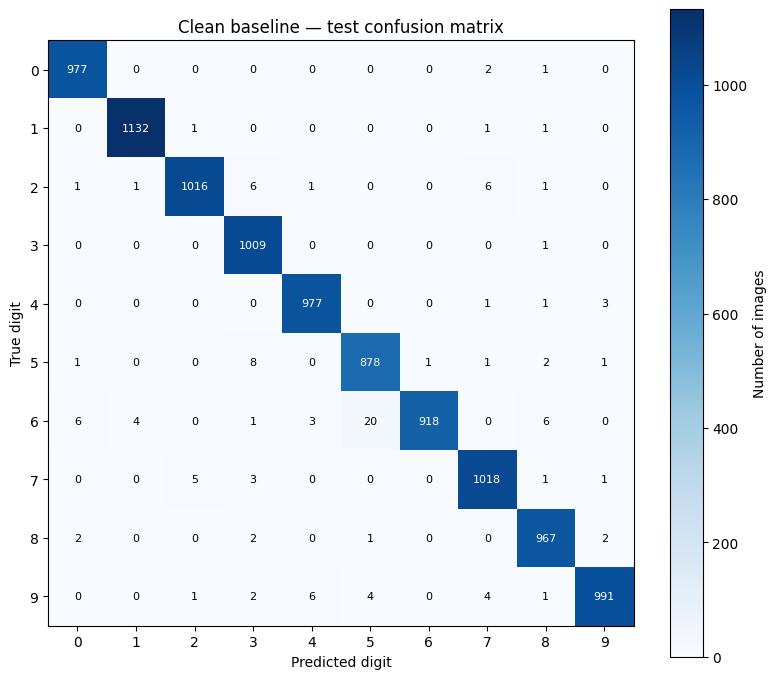

In [ ]:
import matplotlib.pyplot as plt

def plot_confusion_matrix(metrics, title, output_path):
    matrix = np.asarray(metrics["confusion_matrix"])

    fig, ax = plt.subplots(figsize=(8, 7))
    image = ax.imshow(matrix, cmap="Blues")

    for row in range(10):
        for column in range(10):
            value = matrix[row, column]

            ax.text(
                column,
                row,
                str(value),
                ha="center",
                va="center",
                fontsize=8,
                color=(
                    "white"
                    if value > matrix.max() / 2
                    else "black"
                ),
            )

    ax.set(
        xticks=range(10),
        yticks=range(10),
        xlabel="Predicted digit",
        ylabel="True digit",
        title=title,
    )

    fig.colorbar(image, ax=ax, label="Number of images")
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


plot_confusion_matrix(
    baseline_metrics,
    "Clean baseline — test confusion matrix",
    PROJECT_DIR / "results" / "clean_baseline_confusion.png",
)

Train the poisoned conditions


Starting poisoned_010
Epoch 1/5 | train accuracy: 0.9303 | validation accuracy: 0.9774 | validation loss: 0.0865
Epoch 2/5 | train accuracy: 0.9747 | validation accuracy: 0.9862 | validation loss: 0.0660
Epoch 3/5 | train accuracy: 0.9785 | validation accuracy: 0.9858 | validation loss: 0.0568
Epoch 4/5 | train accuracy: 0.9815 | validation accuracy: 0.9864 | validation loss: 0.0666
Epoch 5/5 | train accuracy: 0.9827 | validation accuracy: 0.9878 | validation loss: 0.0543


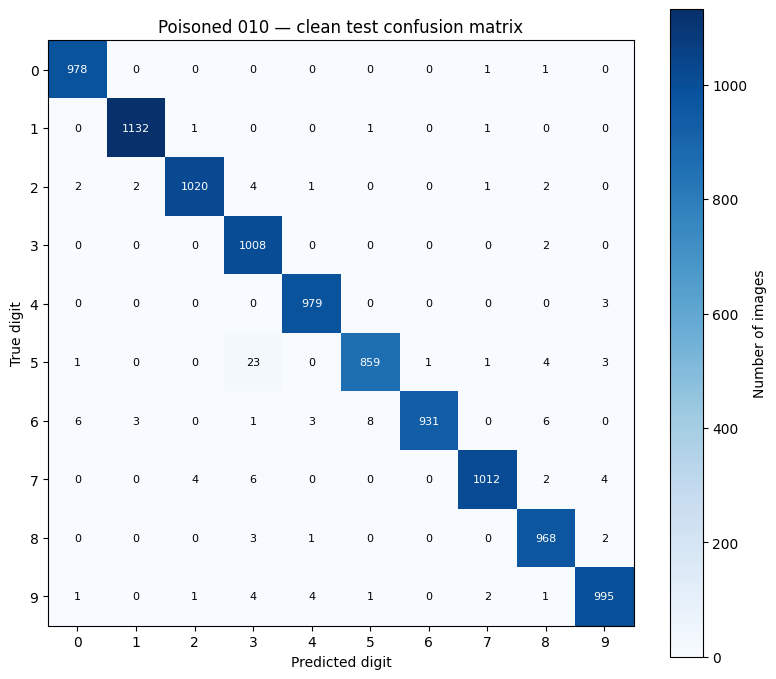

Completed poisoned_010 | accuracy=0.9882 | class 1 recall=0.9974 | 1→7 error=0.0009

Starting poisoned_030
Epoch 1/5 | train accuracy: 0.9043 | validation accuracy: 0.9462 | validation loss: 0.1471
Epoch 2/5 | train accuracy: 0.9505 | validation accuracy: 0.9856 | validation loss: 0.0833
Epoch 3/5 | train accuracy: 0.9558 | validation accuracy: 0.9850 | validation loss: 0.0852
Epoch 4/5 | train accuracy: 0.9583 | validation accuracy: 0.9846 | validation loss: 0.0908
Epoch 5/5 | train accuracy: 0.9598 | validation accuracy: 0.9860 | validation loss: 0.0870


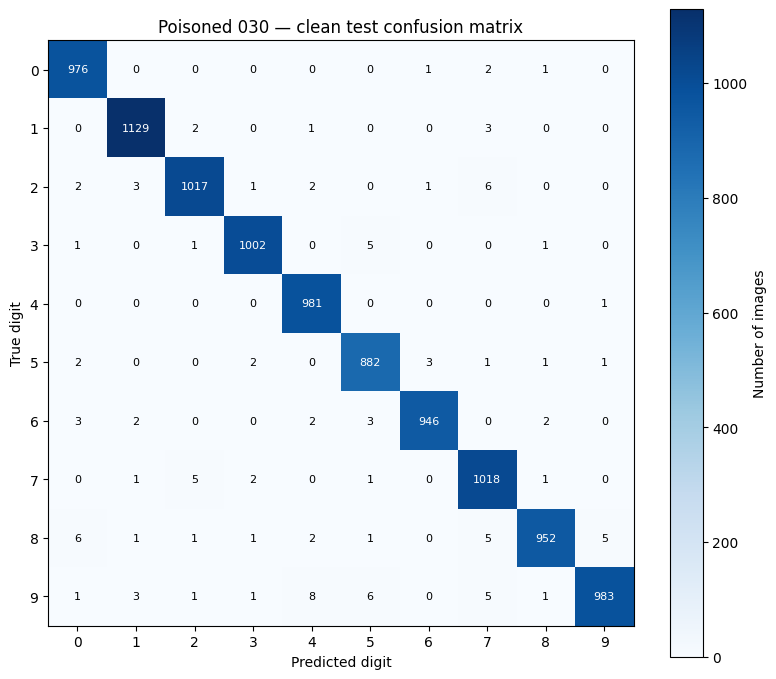

Completed poisoned_030 | accuracy=0.9886 | class 1 recall=0.9947 | 1→7 error=0.0026

Starting poisoned_050
Epoch 1/5 | train accuracy: 0.8854 | validation accuracy: 0.8692 | validation loss: 0.2386
Epoch 2/5 | train accuracy: 0.9292 | validation accuracy: 0.9010 | validation loss: 0.1343
Epoch 3/5 | train accuracy: 0.9337 | validation accuracy: 0.8772 | validation loss: 0.1590
Epoch 4/5 | train accuracy: 0.9372 | validation accuracy: 0.9470 | validation loss: 0.1236
Epoch 5/5 | train accuracy: 0.9383 | validation accuracy: 0.8930 | validation loss: 0.1351


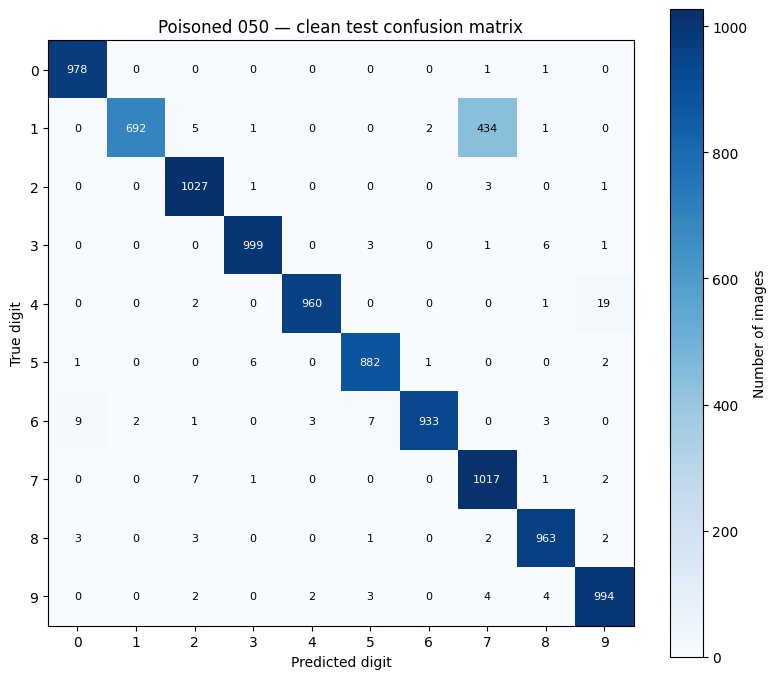

Completed poisoned_050 | accuracy=0.9445 | class 1 recall=0.6097 | 1→7 error=0.3824


In [ ]:
poisoning_results = {}

for tag in ["010", "030", "050"]:
    print(f"\nStarting poisoned_{tag}", flush=True)

    # Load the saved attack artifact.
    attack_file = PROJECT_DIR / "attacks" / (
        f"nested_label_flip_1_to_7_fraction_{tag}.npz"
    )

    with np.load(attack_file, allow_pickle=False) as attack:
        candidate_labels = attack["poisoned_labels"].copy()

    # Confirm that the protected path would reject this candidate.
    gate_result = data_security.verify_training_data(
        train_images,
        candidate_labels,
        trusted_reference,
    )

    if gate_result["accepted"]:
        raise RuntimeError(
            f"Expected poisoned_{tag} to fail integrity verification."
        )

    # Confirm held-out data still matches the clean reference.
    held_out_checks = {
        "validation_images": (
            array_digest(val_images)
            == trusted_reference["validation_images_sha256"]
        ),
        "validation_labels": (
            array_digest(val_labels)
            == trusted_reference["validation_labels_sha256"]
        ),
        "test_images": (
            array_digest(test_images)
            == trusted_reference["test_images_sha256"]
        ),
        "test_labels": (
            array_digest(test_labels)
            == trusted_reference["test_labels_sha256"]
        ),
    }

    if not all(held_out_checks.values()):
        raise RuntimeError("Held-out data changed. Stop the experiment.")

    poisoned_dataset = make_dataset(
        train_images,
        candidate_labels,
    )

    # Deliberately unprotected training for attack evaluation.
    model, history, selected_epoch, elapsed_seconds = (
        train_experiment(
            poisoned_dataset,
            seed=CONFIG["training_seed"],
        )
    )

    metrics = evaluate_model(model, test_loader, device)
    timing = benchmark_inference(model, test_dataset, device)

    result = {
        "condition": f"poisoned_{tag}",
        "protected_gate_would_block": True,
        "training_path": "unprotected attack evaluation",
        "modified_records": int(
            np.count_nonzero(candidate_labels != train_labels)
        ),
        "seed": CONFIG["training_seed"],
        "device": str(device),
        "device_name": baseline_result["device_name"],
        "torch_version": str(torch.__version__),
        "best_epoch": selected_epoch,
        "training_seconds": elapsed_seconds,
        "config": CONFIG,
        "history": history,
        "test_metrics": metrics,
        "inference_timing": timing,
    }

    # Save each condition immediately after completion.
    result_file = (
        PROJECT_DIR / "results" / f"poisoned_{tag}_seed42.json"
    )
    result_file.write_text(json.dumps(result, indent=2))

    model_state = {
        name: tensor.detach().cpu().clone()
        for name, tensor in model.state_dict().items()
    }

    torch.save(
        model_state,
        PROJECT_DIR / "checkpoints" / f"poisoned_{tag}_seed42.pt",
    )

    poisoning_results[tag] = result

    plot_confusion_matrix(
        metrics,
        f"Poisoned {tag} — clean test confusion matrix",
        PROJECT_DIR / "results" / f"poisoned_{tag}_confusion.png",
    )

    print(
        f"Completed poisoned_{tag} | "
        f"accuracy={metrics['accuracy']:.4f} | "
        f"class 1 recall={metrics['class_1_recall']:.4f} | "
        f"1→7 error={metrics['targeted_1_to_7_error_rate']:.4f}",
        flush=True,
    )

    del model, poisoned_dataset, model_state

    if device.type == "cuda":
        torch.cuda.empty_cache()

Generate the comparison table

In [ ]:
import pandas as pd

comparison_rows = []

conditions = [baseline_result] + [
    poisoning_results[tag]
    for tag in ["010", "030", "050"]
]

for result in conditions:
    metrics = result["test_metrics"]

    comparison_rows.append({
        "Condition": result["condition"],
        "Modified labels": result.get("modified_records", 0),
        "Accuracy (%)": 100 * metrics["accuracy"],
        "Loss": metrics["loss"],
        "Class 1 recall (%)": 100 * metrics["class_1_recall"],
        "1→7 error (%)": (
            100 * metrics["targeted_1_to_7_error_rate"]
        ),
        "Median batch inference (ms)": (
            result["inference_timing"]["median_batch_ms"]
        ),
    })

comparison = pd.DataFrame(comparison_rows)

comparison.to_csv(
    PROJECT_DIR / "results" / "poisoning_comparison_seed42.csv",
    index=False,
)

display(comparison.round(4))

,Condition,Modified labels,Accuracy (%),Loss,Class 1 recall (%),1→7 error (%),Median batch inference (ms)
0,clean_baseline,0,98.83,0.0375,99.7357,0.0881,108.5297
1,poisoned_010,619,98.82,0.0525,99.7357,0.0881,117.2495
2,poisoned_030,1857,98.86,0.0709,99.4714,0.2643,115.7240
3,poisoned_050,3095,94.45,0.1170,60.9692,38.2379,101.8379


Reload and verify the recovery snapshot

In [ ]:
recovery_path = (
    PROJECT_DIR / "trusted" / "clean_training_snapshot.npz"
)

with np.load(recovery_path, allow_pickle=False) as saved:
    recovered_images = saved["images"].copy()
    recovered_labels = saved["labels"].copy()

recovery_check = data_security.require_verified_training_data(
    recovered_images,
    recovered_labels,
    trusted_reference,
)

print("Recovered training data: VERIFIED")

Recovered training data: VERIFIED


**Train the defended model:**
This represents blocking the poisoned candidate, restoring the trusted snapshot, verifying it, and then training. It does not train directly on the rejected data.

Epoch 1/5 | train accuracy: 0.9407 | validation accuracy: 0.9782 | validation loss: 0.0730
Epoch 2/5 | train accuracy: 0.9847 | validation accuracy: 0.9866 | validation loss: 0.0506
Epoch 3/5 | train accuracy: 0.9895 | validation accuracy: 0.9876 | validation loss: 0.0411
Epoch 4/5 | train accuracy: 0.9925 | validation accuracy: 0.9866 | validation loss: 0.0498
Epoch 5/5 | train accuracy: 0.9933 | validation accuracy: 0.9884 | validation loss: 0.0406


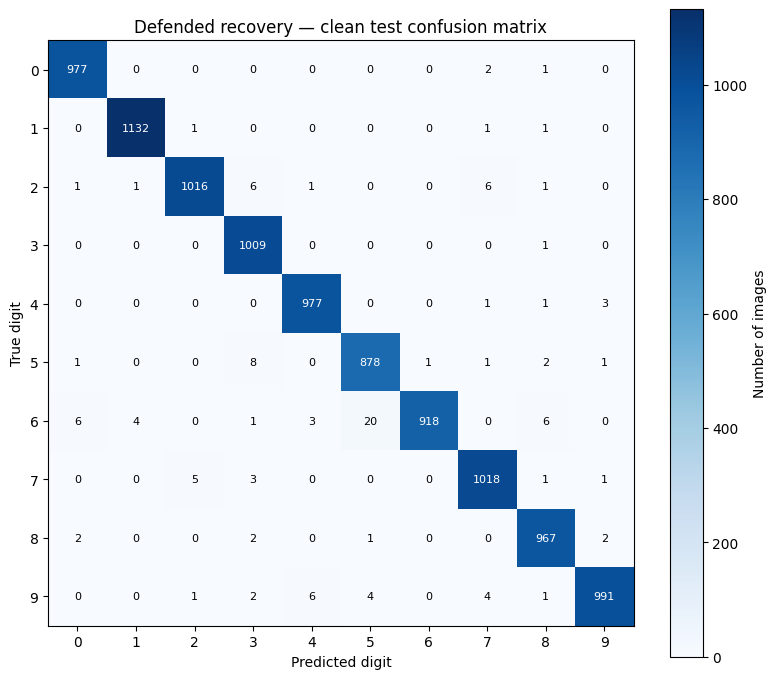

Selected epoch: 5
Test accuracy: 0.9883
Test loss: 0.03749657526891679
Class 1 recall: 0.9973568281938326
1 → 7 error rate: 0.000881057268722467


In [ ]:
recovered_dataset = make_dataset(
    recovered_images,
    recovered_labels,
)

defended_model, defended_history, defended_epoch, defended_seconds = (
    train_experiment(
        recovered_dataset,
        seed=CONFIG["training_seed"],
    )
)

defended_metrics = evaluate_model(
    defended_model,
    test_loader,
    device,
)

defended_timing = benchmark_inference(
    defended_model,
    test_dataset,
    device,
)

defended_result = {
    "condition": "defended_recovery",
    "defense": "integrity gate followed by trusted snapshot recovery",
    "rejected_attack": "poisoned_050",
    "training_data_verified": recovery_check["accepted"],
    "modified_records": 0,
    "seed": CONFIG["training_seed"],
    "device": str(device),
    "device_name": (
        torch.cuda.get_device_name(0)
        if device.type == "cuda"
        else "CPU"
    ),
    "torch_version": str(torch.__version__),
    "best_epoch": defended_epoch,
    "training_seconds": defended_seconds,
    "config": CONFIG,
    "history": defended_history,
    "test_metrics": defended_metrics,
    "inference_timing": defended_timing,
}

defended_result_path = (
    PROJECT_DIR / "results" / "defended_recovery_seed42.json"
)
defended_result_path.write_text(
    json.dumps(defended_result, indent=2)
)

defended_state = {
    name: tensor.detach().cpu().clone()
    for name, tensor in defended_model.state_dict().items()
}

torch.save(
    defended_state,
    PROJECT_DIR / "checkpoints" / "defended_recovery_seed42.pt",
)

plot_confusion_matrix(
    defended_metrics,
    "Defended recovery — clean test confusion matrix",
    PROJECT_DIR / "results" / "defended_recovery_confusion.png",
)

print("Selected epoch:", defended_epoch)
print("Test accuracy:", defended_metrics["accuracy"])
print("Test loss:", defended_metrics["loss"])
print("Class 1 recall:", defended_metrics["class_1_recall"])
print(
    "1 → 7 error rate:",
    defended_metrics["targeted_1_to_7_error_rate"],
)

Save the complete comparison

In [35]:
result_filenames = [
    "clean_baseline_seed42.json",
    "poisoned_010_seed42.json",
    "poisoned_030_seed42.json",
    "poisoned_050_seed42.json",
    "defended_recovery_seed42.json",
]

complete_rows = []

for filename in result_filenames:
    result = json.loads(
        (PROJECT_DIR / "results" / filename).read_text()
    )
    metrics = result["test_metrics"]

    complete_rows.append({
        "Condition": result["condition"],
        "Modified training labels": result.get("modified_records", 0),
        "Accuracy (%)": 100 * metrics["accuracy"],
        "Loss": metrics["loss"],
        "Class 1 recall (%)": 100 * metrics["class_1_recall"],
        "1→7 error (%)": (
            100 * metrics["targeted_1_to_7_error_rate"]
        ),
        "Median batch inference (ms)": (
            result["inference_timing"]["median_batch_ms"]
        ),
    })

complete_comparison = pd.DataFrame(complete_rows)

complete_comparison.to_csv(
    PROJECT_DIR / "results" / "complete_comparison_seed42.csv",
    index=False,
)

display(complete_comparison.round(4))

,Condition,Modified training labels,Accuracy (%),Loss,Class 1 recall (%),1→7 error (%),Median batch inference (ms)
0,clean_baseline,0,98.83,0.0375,99.7357,0.0881,108.5297
1,poisoned_010,619,98.82,0.0525,99.7357,0.0881,117.2495
2,poisoned_030,1857,98.86,0.0709,99.4714,0.2643,115.7240
3,poisoned_050,3095,94.45,0.1170,60.9692,38.2379,101.8379
4,defended_recovery,0,98.83,0.0375,99.7357,0.0881,106.1738


Export the training code

In [37]:
import ast
import textwrap

training_module_path = PROJECT_DIR / "src" / "mnist_training.py"

names_to_export = [
    "MNISTCNN",
    "make_dataset",
    "set_training_seed",
    "evaluate_model",
    "train_experiment",
    "benchmark_inference",
]

# Find the latest executed definition of each requested object.
definitions = {}

for cell_source in get_ipython().history_manager.input_hist_raw:
    try:
        tree = ast.parse(cell_source)
    except SyntaxError:
        # Skip cells containing notebook magic or shell commands.
        continue

    for node in tree.body:
        if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
            if node.name not in names_to_export:
                continue

            # Include decorators such as @torch.inference_mode().
            first_line = min(
                [node.lineno]
                + [
                    decorator.lineno
                    for decorator in node.decorator_list
                ]
            )

            lines = cell_source.splitlines(keepends=True)

            definitions[node.name] = "".join(
                lines[first_line - 1:node.end_lineno]
            )

missing = [
    name for name in names_to_export
    if name not in definitions
]

if missing:
    raise RuntimeError(
        "Definitions missing from this session's history: "
        + ", ".join(missing)
        + ". Rerun their definition cells, then retry. "
          "You do not need to rerun training."
    )

module_header = textwrap.dedent('''
    """Shared MNIST model, training, and evaluation utilities.

    Before calling train_experiment, explicitly assign:
        CONFIG
        device
        validation_loader

    Protected training callers must verify data before training.
    """

    import random
    import time
    import numpy as np
    import torch

    from torch import nn
    from torch.utils.data import TensorDataset, DataLoader
''').lstrip()

training_source = module_header + "\n\n" + "\n\n".join(
    definitions[name]
    for name in names_to_export
)

ast.parse(training_source)

training_module_path.write_text(
    training_source,
    encoding="utf-8",
)

print("Saved:", training_module_path.name)
print("Syntax check: PASS")
print("Exported definitions:", ", ".join(names_to_export))

Saved: mnist_training.py
Syntax check: PASS
Exported definitions: MNISTCNN, make_dataset, set_training_seed, evaluate_model, train_experiment, benchmark_inference


Check that the exported model behaves identically

In [38]:
training_spec = importlib.util.spec_from_file_location(
    "mnist_training",
    training_module_path,
)

training_module = importlib.util.module_from_spec(training_spec)
training_spec.loader.exec_module(training_module)

exported_model = training_module.MNISTCNN().to(device)
exported_model.load_state_dict(baseline_model.state_dict())
exported_model.eval()
baseline_model.eval()

sample_images = test_dataset.tensors[0][:32].to(device)

with torch.inference_mode():
    original_logits = baseline_model(sample_images)
    exported_logits = exported_model(sample_images)

torch.testing.assert_close(
    original_logits,
    exported_logits,
)

print("Exported model output matches: PASS")

del exported_model

Exported model output matches: PASS


Scan both modules

In [39]:
src_directory = PROJECT_DIR / "src"
full_scan_path = PROJECT_DIR / "sast" / "modules_initial.json"

scan_command = [
    sys.executable,
    "-m",
    "bandit",
    "-r",
    str(src_directory),
    "-f",
    "json",
    "-o",
    str(full_scan_path),
]

scan_process = subprocess.run(
    scan_command,
    capture_output=True,
    text=True,
)

if scan_process.returncode not in (0, 1):
    raise RuntimeError(
        scan_process.stdout + scan_process.stderr
    )

full_report = json.loads(full_scan_path.read_text())

if full_report.get("errors"):
    raise RuntimeError(
        json.dumps(full_report["errors"], indent=2)
    )

findings = full_report.get("results", [])

source_hashes = {
    str(path.relative_to(src_directory)): hashlib.sha256(
        path.read_bytes()
    ).hexdigest()
    for path in sorted(src_directory.rglob("*.py"))
}

version_process = subprocess.run(
    [sys.executable, "-m", "bandit", "--version"],
    capture_output=True,
    text=True,
    check=True,
)

metadata = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "scope": "Python modules under src; notebook cells excluded",
    "command": scan_command,
    "exit_code": scan_process.returncode,
    "bandit_version": (
        version_process.stdout + version_process.stderr
    ).strip(),
    "source_hashes": source_hashes,
    "finding_count": len(findings),
}

(PROJECT_DIR / "sast" / "modules_initial_metadata.json").write_text(
    json.dumps(metadata, indent=2)
)

# Preserve the exact module files associated with this scan.
snapshot_directory = (
    PROJECT_DIR / "sast" / "modules_initial_source"
)
snapshot_directory.mkdir(exist_ok=True)

for path in sorted(src_directory.rglob("*.py")):
    destination = snapshot_directory / path.relative_to(src_directory)
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_bytes(path.read_bytes())

print("Scanned modules:")
for filename in source_hashes:
    print("-", filename)

print("\nFindings:", len(findings))

for finding in findings:
    print(
        f"\n{Path(finding['filename']).name}:"
        f"{finding['line_number']} | "
        f"{finding['test_id']} | "
        f"Severity: {finding['issue_severity']} | "
        f"Confidence: {finding['issue_confidence']}"
    )
    print(finding["issue_text"])

print("\nScan evidence saved.")

Scanned modules:
- data_security.py
- mnist_training.py

Findings: 0

Scan evidence saved.


Upload that snapshot for scanning

In [40]:
from google.colab import files

uploaded_notebooks = files.upload()

notebook_names = [
    name for name in uploaded_notebooks
    if name.endswith(".ipynb")
]

if len(notebook_names) != 1:
    raise ValueError("Upload exactly one .ipynb notebook.")

notebook_name = notebook_names[0]
notebook_bytes = uploaded_notebooks[notebook_name]

print("Notebook selected:", notebook_name)

Saving Ayush_MNIST_Security.ipynb to Ayush_MNIST_Security.ipynb
Notebook selected: Ayush_MNIST_Security.ipynb


In [41]:
import nbformat
from nbconvert import PythonExporter

notebook = nbformat.reads(
    notebook_bytes.decode("utf-8"),
    as_version=4,
)

exporter = PythonExporter()
notebook_source, _ = exporter.from_notebook_node(notebook)

# Store separately from src to avoid duplicating module scan scope.
notebook_scan_dir = PROJECT_DIR / "sast" / "notebook_initial"
notebook_scan_dir.mkdir(exist_ok=True)

notebook_snapshot_path = (
    notebook_scan_dir / "notebook_snapshot.ipynb"
)
notebook_snapshot_path.write_bytes(notebook_bytes)

notebook_script_path = (
    notebook_scan_dir / "notebook_export.py"
)
notebook_script_path.write_text(
    notebook_source,
    encoding="utf-8",
)

code_cell_count = sum(
    cell.cell_type == "code"
    for cell in notebook.cells
)

print("Code cells exported:", code_cell_count)
print("Saved:", notebook_script_path.name)
print("The exported script has NOT been executed.")

Code cells exported: 40
Saved: notebook_export.py
The exported script has NOT been executed.


In [42]:
notebook_report_path = (
    notebook_scan_dir / "bandit_report.json"
)

notebook_scan_command = [
    sys.executable,
    "-m",
    "bandit",
    str(notebook_script_path),
    "-f",
    "json",
    "-o",
    str(notebook_report_path),
]

notebook_scan_process = subprocess.run(
    notebook_scan_command,
    capture_output=True,
    text=True,
)

if notebook_scan_process.returncode not in (0, 1):
    raise RuntimeError(
        notebook_scan_process.stdout
        + notebook_scan_process.stderr
    )

notebook_report = json.loads(
    notebook_report_path.read_text()
)

if notebook_report.get("errors"):
    raise RuntimeError(
        json.dumps(notebook_report["errors"], indent=2)
    )

notebook_findings = notebook_report.get("results", [])

bandit_version_process = subprocess.run(
    [sys.executable, "-m", "bandit", "--version"],
    capture_output=True,
    text=True,
    check=True,
)

notebook_scan_metadata = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "scope": "Downloaded notebook snapshot exported to Python",
    "original_filename": notebook_name,
    "code_cell_count": code_cell_count,
    "notebook_sha256": hashlib.sha256(
        notebook_bytes
    ).hexdigest(),
    "exported_script_sha256": hashlib.sha256(
        notebook_script_path.read_bytes()
    ).hexdigest(),
    "bandit_version": (
        bandit_version_process.stdout
        + bandit_version_process.stderr
    ).strip(),
    "command": notebook_scan_command,
    "exit_code": notebook_scan_process.returncode,
    "finding_count": len(notebook_findings),
    "limitations": [
        "Covers the downloaded snapshot, not subsequent edits.",
        "Notebook magic and shell commands may be exported as "
        "IPython calls rather than directly analyzed Python.",
        "Does not audit installed dependencies or Google Drive permissions.",
    ],
}

(notebook_scan_dir / "scan_metadata.json").write_text(
    json.dumps(notebook_scan_metadata, indent=2)
)

print("Notebook findings:", len(notebook_findings))

for finding in notebook_findings:
    print(
        f"\nLine {finding['line_number']} | "
        f"{finding['test_id']} | "
        f"Severity: {finding['issue_severity']} | "
        f"Confidence: {finding['issue_confidence']}"
    )
    print("Issue:", finding["issue_text"])
    print("Code:\n", finding["code"])

print("\nNotebook scan evidence saved.")

Notebook findings: 5

Line 805 | B404 | Severity: LOW | Confidence: HIGH
Issue: Consider possible security implications associated with the subprocess module.
Code:
 804 
805 import subprocess
806 from datetime import datetime, timezone


Line 808 | B603 | Severity: LOW | Confidence: HIGH
Issue: subprocess call - check for execution of untrusted input.
Code:
 807 
808 version_process = subprocess.run(
809     [sys.executable, "-m", "bandit", "--version"],
810     capture_output=True,
811     text=True,
812     check=True,
813 )
814 


Line 830 | B603 | Severity: LOW | Confidence: HIGH
Issue: subprocess call - check for execution of untrusted input.
Code:
 829 
830 scan_process = subprocess.run(
831     command,
832     capture_output=True,
833     text=True,
834 )
835 


Line 1855 | B603 | Severity: LOW | Confidence: HIGH
Issue: subprocess call - check for execution of untrusted input.
Code:
 1854 
1855 scan_process = subprocess.run(
1856     scan_command,
1857     capture_output=True,

In [43]:
review_rows = []

for finding in notebook_findings:
    test_id = finding["test_id"]

    if test_id == "B404":
        disposition = "Reviewed: informational module-import warning"
        rationale = (
            "subprocess is used to invoke the Bandit security scanner. "
            "The import alone does not execute a command."
        )
    elif test_id == "B603":
        disposition = "Reviewed: no exploitable issue identified in this use"
        rationale = (
            "Reviewed command definitions use sys.executable with "
            "the fixed '-m bandit' module and controlled arguments. "
            "Commands are passed as argument lists with shell=False "
            "by default. The modeled attacker cannot alter these "
            "command definitions or arguments."
        )
    else:
        disposition = "Pending review"
        rationale = "Requires separate review."

    review_rows.append({
        "test_id": test_id,
        "line_number": finding["line_number"],
        "severity": finding["issue_severity"],
        "confidence": finding["issue_confidence"],
        "issue": finding["issue_text"],
        "disposition": disposition,
        "rationale": rationale,
        "code_change": "None",
    })

review_table = pd.DataFrame(review_rows)

review_table.to_csv(
    notebook_scan_dir / "findings_review.csv",
    index=False,
)

display(
    review_table[
        ["test_id", "line_number", "severity", "disposition"]
    ]
)

print("Findings review saved.")

,test_id,line_number,severity,disposition
0,B404,805,LOW,Reviewed: informational module-import warning
1,B603,808,LOW,Reviewed: no exploitable issue identified in t...
2,B603,830,LOW,Reviewed: no exploitable issue identified in t...
3,B603,1855,LOW,Reviewed: no exploitable issue identified in t...
4,B603,1882,LOW,Reviewed: no exploitable issue identified in t...


Findings review saved.


## SAST findings and review

Tool: Bandit 1.9.4.

Scope:
- data_security.py: 0 findings.
- mnist_training.py: 0 findings.
- Notebook snapshot exported to Python, containing 40 code cells:
  5 LOW-severity findings.

Notebook findings:
- One B404 warning for importing subprocess.
- Four B603 warnings for subprocess.run calls used to launch
  Bandit scans or retrieve the Bandit version.

Review:
The subprocess calls use argument lists, a fixed Python executable,
and the Bandit module. Shell execution is disabled by default.
Command arguments are controlled by the notebook and are outside
the modeled data-poisoning attacker's permissions.

No exploitable issue was identified in these five uses, so no code
changes or suppressions were applied. Raw findings, source snapshots,
hashes, and review decisions were retained.

Limitations:
This is static analysis of the recorded source snapshots, not proof
of application security. It does not audit dependencies, runtime
permissions, or all behavior inside notebook shell/magic commands.

In [44]:
import copy
import platform

# Confirm the clean training data still matches the trusted reference.
data_security.require_verified_training_data(
    train_images,
    train_labels,
    trusted_reference,
)

# Confirm validation and test data are unchanged.
for images, labels, prefix in [
    (val_images, val_labels, "validation"),
    (test_images, test_labels, "test"),
]:
    if (
        array_digest(images)
        != trusted_reference[f"{prefix}_images_sha256"]
        or array_digest(labels)
        != trusted_reference[f"{prefix}_labels_sha256"]
    ):
        raise RuntimeError(f"{prefix} data changed.")

# Prepare candidate labels from the saved attack files.
repeat_conditions = {
    "clean_baseline": train_labels,
}

for tag in ["010", "030", "050"]:
    attack_path = PROJECT_DIR / "attacks" / (
        f"nested_label_flip_1_to_7_fraction_{tag}.npz"
    )

    with np.load(attack_path, allow_pickle=False) as saved:
        labels = saved["poisoned_labels"].copy()

    gate = data_security.verify_training_data(
        train_images,
        labels,
        trusted_reference,
    )

    if gate["accepted"]:
        raise RuntimeError(f"Poisoned condition {tag} was accepted.")

    repeat_conditions[f"poisoned_{tag}"] = labels


def run_additional_seed(training_seed):
    if training_seed not in (43, 44):
        raise ValueError("This runner is reserved for seeds 43 and 44.")

    # The existing training function uses CONFIG as a global.
    # Copy it temporarily, then restore it when this runner finishes.
    original_config = CONFIG
    run_config = copy.deepcopy(original_config)
    run_config["training_seed"] = training_seed

    train_experiment.__globals__["CONFIG"] = run_config

    try:
        for condition, candidate_labels in repeat_conditions.items():
            result_path = PROJECT_DIR / "results" / (
                f"{condition}_seed{training_seed}.json"
            )
            checkpoint_path = PROJECT_DIR / "checkpoints" / (
                f"{condition}_seed{training_seed}.pt"
            )

            # Skip completed runs; never overwrite them.
            if result_path.exists():
                existing = json.loads(result_path.read_text())

                if (
                    existing.get("condition") != condition
                    or existing.get("seed") != training_seed
                    or existing.get("config") != run_config
                    or not checkpoint_path.exists()
                ):
                    raise RuntimeError(
                        f"Inconsistent existing output for "
                        f"{condition}, seed {training_seed}. "
                        "Stop and review before continuing."
                    )

                print(
                    f"SKIPPED completed run: "
                    f"{condition}, seed {training_seed}",
                    flush=True,
                )
                continue

            if checkpoint_path.exists():
                raise RuntimeError(
                    f"Checkpoint exists without a result: "
                    f"{checkpoint_path.name}. "
                    "Stop and review before continuing."
                )

            if condition == "clean_baseline":
                data_security.require_verified_training_data(
                    train_images,
                    candidate_labels,
                    trusted_reference,
                )

            print(
                f"\nSTARTING {condition}, seed {training_seed}",
                flush=True,
            )

            dataset = make_dataset(
                train_images,
                candidate_labels,
            )

            # Poisoned conditions intentionally use the unprotected
            # path to measure the attack's effect.
            model, history, best_epoch, elapsed = train_experiment(
                dataset,
                seed=training_seed,
            )

            metrics = evaluate_model(model, test_loader, device)
            timing = benchmark_inference(
                model, test_dataset, device
            )

            result = {
                "condition": condition,
                "seed": training_seed,
                "modified_records": int(
                    np.count_nonzero(
                        candidate_labels != train_labels
                    )
                ),
                "training_path": (
                    "integrity-verified clean training"
                    if condition == "clean_baseline"
                    else "unprotected attack evaluation"
                ),
                "protected_gate_would_block": (
                    condition != "clean_baseline"
                ),
                "device": str(device),
                "device_name": (
                    torch.cuda.get_device_name(0)
                    if device.type == "cuda"
                    else "CPU"
                ),
                "cpu_description": platform.processor(),
                "torch_threads": torch.get_num_threads(),
                "torch_version": str(torch.__version__),
                "best_epoch": best_epoch,
                "training_seconds": elapsed,
                "config": copy.deepcopy(run_config),
                "history": history,
                "test_metrics": metrics,
                "inference_timing": timing,
            }

            state = {
                name: tensor.detach().cpu().clone()
                for name, tensor in model.state_dict().items()
            }

            # Exclusive creation: existing files cannot be overwritten.
            with checkpoint_path.open("xb") as handle:
                torch.save(state, handle)

            with result_path.open("x", encoding="utf-8") as handle:
                json.dump(result, handle, indent=2)

            print(
                f"COMPLETED {condition}, seed {training_seed} | "
                f"accuracy={metrics['accuracy']:.4f} | "
                f"class 1 recall={metrics['class_1_recall']:.4f} | "
                f"1→7 error="
                f"{metrics['targeted_1_to_7_error_rate']:.4f}",
                flush=True,
            )

            del model, dataset, state

            if device.type == "cuda":
                torch.cuda.empty_cache()

    finally:
        train_experiment.__globals__["CONFIG"] = original_config


print("Ready. Earlier results have not been changed.")
print("Split seed: 42; attack seed: 42.")
print("Additional training seeds: 43 and 44.")

Ready. Earlier results have not been changed.
Split seed: 42; attack seed: 42.
Additional training seeds: 43 and 44.


In [45]:
run_additional_seed(43)


STARTING clean_baseline, seed 43
Epoch 1/5 | train accuracy: 0.9407 | validation accuracy: 0.9784 | validation loss: 0.0737
Epoch 2/5 | train accuracy: 0.9830 | validation accuracy: 0.9846 | validation loss: 0.0490
Epoch 3/5 | train accuracy: 0.9881 | validation accuracy: 0.9868 | validation loss: 0.0427
Epoch 4/5 | train accuracy: 0.9914 | validation accuracy: 0.9890 | validation loss: 0.0380
Epoch 5/5 | train accuracy: 0.9932 | validation accuracy: 0.9876 | validation loss: 0.0432
COMPLETED clean_baseline, seed 43 | accuracy=0.9904 | class 1 recall=0.9956 | 1→7 error=0.0000

STARTING poisoned_010, seed 43
Epoch 1/5 | train accuracy: 0.9282 | validation accuracy: 0.9778 | validation loss: 0.0912
Epoch 2/5 | train accuracy: 0.9724 | validation accuracy: 0.9844 | validation loss: 0.0624
Epoch 3/5 | train accuracy: 0.9772 | validation accuracy: 0.9864 | validation loss: 0.0565
Epoch 4/5 | train accuracy: 0.9805 | validation accuracy: 0.9876 | validation loss: 0.0491
Epoch 5/5 | train ac

In [48]:
run_additional_seed(44)

SKIPPED completed run: clean_baseline, seed 44
SKIPPED completed run: poisoned_010, seed 44

STARTING poisoned_030, seed 44
Epoch 1/5 | train accuracy: 0.9030 | validation accuracy: 0.9736 | validation loss: 0.1142
Epoch 2/5 | train accuracy: 0.9482 | validation accuracy: 0.9850 | validation loss: 0.0744
Epoch 3/5 | train accuracy: 0.9544 | validation accuracy: 0.9832 | validation loss: 0.1034
Epoch 4/5 | train accuracy: 0.9573 | validation accuracy: 0.9870 | validation loss: 0.0701
Epoch 5/5 | train accuracy: 0.9596 | validation accuracy: 0.9876 | validation loss: 0.0855
COMPLETED poisoned_030, seed 44 | accuracy=0.9879 | class 1 recall=0.9930 | 1→7 error=0.0035

STARTING poisoned_050, seed 44
Epoch 1/5 | train accuracy: 0.8847 | validation accuracy: 0.9610 | validation loss: 0.1488
Epoch 2/5 | train accuracy: 0.9290 | validation accuracy: 0.9656 | validation loss: 0.1188
Epoch 3/5 | train accuracy: 0.9333 | validation accuracy: 0.9480 | validation loss: 0.1311
Epoch 4/5 | train accur

In [49]:
print("hei")

hei


In [50]:
rows = []

for seed in [42, 43, 44]:
    for condition in [
        "clean_baseline",
        "poisoned_010",
        "poisoned_030",
        "poisoned_050",
    ]:
        path = PROJECT_DIR / "results" / (
            f"{condition}_seed{seed}.json"
        )

        result = json.loads(path.read_text())
        metrics = result["test_metrics"]

        rows.append({
            "Condition": condition,
            "Seed": seed,
            "Accuracy (%)": 100 * metrics["accuracy"],
            "Loss": metrics["loss"],
            "Class 1 recall (%)": (
                100 * metrics["class_1_recall"]
            ),
            "1→7 error (%)": (
                100 * metrics["targeted_1_to_7_error_rate"]
            ),
        })

repeated_results = pd.DataFrame(rows)

summary = repeated_results.groupby(
    "Condition", sort=False
)[
    [
        "Accuracy (%)",
        "Loss",
        "Class 1 recall (%)",
        "1→7 error (%)",
    ]
].agg(["mean", "std"])

# Versioned filenames preserve any earlier summary.
summary_tag = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S%fZ"
)

repeated_results.to_csv(
    PROJECT_DIR / "results" / f"three_seed_runs_{summary_tag}.csv",
    index=False,
)

summary.to_csv(
    PROJECT_DIR / "results" / f"three_seed_summary_{summary_tag}.csv"
)

print("Individual runs:")
display(repeated_results.round(4))

print("\nMean and sample standard deviation across three training seeds:")
display(summary.round(4))

Individual runs:


,Condition,Seed,Accuracy (%),Loss,Class 1 recall (%),1→7 error (%)
0,clean_baseline,42,98.83,0.0375,99.7357,0.0881
1,poisoned_010,42,98.82,0.0525,99.7357,0.0881
2,poisoned_030,42,98.86,0.0709,99.4714,0.2643
3,poisoned_050,42,94.45,0.1170,60.9692,38.2379
4,clean_baseline,43,99.04,0.0312,99.5595,0.0000
5,poisoned_010,43,98.89,0.0476,98.9427,0.2643
6,poisoned_030,43,98.93,0.0706,99.3833,0.3524
7,poisoned_050,43,96.62,0.0991,78.9427,20.7048
8,clean_baseline,44,98.87,0.0330,100.0000,0.0000
9,poisoned_010,44,98.85,0.0405,100.0000,0.0000



Mean and sample standard deviation across three training seeds:


Accuracy (%)            Loss         Class 1 recall (%)  \
                       mean     std    mean     std               mean   
Condition                                                                
clean_baseline      98.9133  0.1115  0.0339  0.0033            99.7651   
poisoned_010        98.8533  0.0351  0.0468  0.0061            99.5595   
poisoned_030        98.8600  0.0700  0.0669  0.0067            99.3833   
poisoned_050        96.0067  1.3582  0.1081  0.0090            74.6549   

                        1→7 error (%)           
                    std          mean      std  
Condition                                       
clean_baseline   0.2217        0.0294   0.0509  
poisoned_010     0.5502        0.1175   0.1346  
poisoned_030     0.0881        0.3231   0.0509  
poisoned_050    12.1245       24.8752  11.8417

In [51]:
import zipfile
from google.colab import files

package_path = Path("/content/Person2_MNIST_Evidence.zip")

folders_to_include = [
    "config",
    "src",
    "results",
    "sast",
]

with zipfile.ZipFile(
    package_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    for folder in folders_to_include:
        for path in sorted((PROJECT_DIR / folder).rglob("*")):
            if (
                path.is_file()
                and "__pycache__" not in path.parts
            ):
                archive.write(
                    path,
                    arcname=str(path.relative_to(PROJECT_DIR)),
                )

print("Created:", package_path.name)
files.download(str(package_path))

Created: Person2_MNIST_Evidence.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
import zipfile
from pathlib import Path

package_zip = Path("/content/Person2_MNIST_Package.zip")

with zipfile.ZipFile(package_zip, "r") as archive:
    archive.extractall("/content")

PACKAGE_DIR = Path("/content/Person2_MNIST_Package")

print("Module exists:",
      (PACKAGE_DIR / "src" / "mnist_training.py").exists())

Module exists: True


In [58]:
import importlib.util

spec = importlib.util.spec_from_file_location(
    "revised_mnist_training",
    PACKAGE_DIR / "src" / "mnist_training.py",
)

revised = importlib.util.module_from_spec(spec)
spec.loader.exec_module(revised)

model = revised.MNISTCNN().to(device)
model.load_state_dict(baseline_model.state_dict())

model.eval()
baseline_model.eval()

with torch.inference_mode():
    sample_images = test_dataset.tensors[0][:32].to(device)

    torch.testing.assert_close(
        model(sample_images),
        baseline_model(sample_images),
    )

print("Model parity: PASS")

Model parity: PASS


In [59]:
from torch.utils.data import Subset, DataLoader

smoke_config = dict(CONFIG, epochs=1)

small_train = Subset(clean_train_dataset, range(64))

small_validation_loader = DataLoader(
    Subset(validation_dataset, range(64)),
    batch_size=64,
    shuffle=False,
)

smoke_model, _, _, _ = revised.train_experiment(
    small_train,
    seed=42,
    config=smoke_config,
    device=device,
    validation_loader=small_validation_loader,
)

print("Explicit training interface: PASS")

Epoch 1/1 | train accuracy: 0.0781 | validation accuracy: 0.2031 | validation loss: 2.2844
Explicit training interface: PASS
